In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

In [3]:
model_comparison = np.load('../variables/model_comparison.npy', allow_pickle=True)

comparison_df = pd.DataFrame(model_comparison, columns=[
    'Language',
    'Product',
    'Actual',
    'Word TF-IDF LR',
    'Char TF-IDF LR',
    'Char TF-IDF SVM',
    'XLM-R',
    'Word TF-IDF LR Correct',
    'Char TF-IDF LR Correct',
    'Char TF-IDF SVM Correct',
    'XLM-R Correct'
])

Linguistic Features: Chinese, Indonesian, or Mix

In [4]:
def identify_language(text):
    text = str(text)

    han_count = len(re.findall(r'[\u4e00-\u9fff]', text))
    latin_count = len(re.findall(r'[1-zA-Z]', text))

    total = han_count + latin_count

    if total == 0:
        return 'Other'

    han_ratio = han_count / total

    if han_ratio > 0.8:
        return 'Chinese'
    elif han_ratio < 0.05:
        return 'Indonesian'
    else:
        return 'Mixed'

comparison_df['Identified Language'] = comparison_df['Product'].apply(identify_language)

Linguistic Features: Text Length

In [5]:
comparison_df['Text Length'] = comparison_df['Product'].astype(str).apply(len)

comparison_df['Word Count'] = comparison_df['Product'].astype(str).apply(
    lambda x: len(x.split())
)


Linguistic Features: Numbers and Product Codes

In [6]:
comparison_df['Numbers'] = comparison_df['Product'].astype(str).apply(
    lambda x: bool(re.search(r'\d', x))
)

comparison_df['Characters'] = comparison_df['Product'].astype(str).apply(
    lambda x: bool(re.search(r'[^a-zA-Z0\s\u4e00-\u9fff]', x))
)

comparison_df

,Language,Product,Actual,Word TF-IDF LR,Char TF-IDF LR,Char TF-IDF SVM,XLM-R,Word TF-IDF LR Correct,Char TF-IDF LR Correct,Char TF-IDF SVM Correct,XLM-R Correct,Identified Language,Text Length,Word Count,Numbers,Characters
0,zh,便携式投影仪,IT,IT,Electrical,Electrical,IT,True,False,False,True,Chinese,6,1,False,False
1,id,map tulang ukuran A4,Office Supplies,Office Supplies,Safety Equipment,Office Supplies,Office Supplies,True,False,True,True,Indonesian,20,4,True,True
2,id,lampu sorot tanam untuk koridor,Electrical,Electrical,Electrical,Electrical,Safety Equipment,True,True,True,False,Indonesian,31,5,False,False
3,id,buku agenda ukran A5,Office Supplies,IT,Tools & Hardware,Tools & Hardware,Office Supplies,False,False,False,True,Indonesian,20,4,True,True
4,id,baut kecil segi enam,Tools & Hardware,Tools & Hardware,Office Supplies,Tools & Hardware,Office Supplies,True,False,True,False,Indonesian,20,4,False,False
5,zh,钢丝钳8寸,Tools & Hardware,IT,Tools & Hardware,Tools & Hardware,IT,False,True,True,False,Mixed,5,1,True,True
6,zh,防降噪耳罩,Safety Equipment,IT,IT,IT,IT,False,False,False,False,Chinese,5,1,False,False
7,zh,复合式洗眼器12L/min,Safety Equipment,IT,Safety Equipment,Safety Equipment,IT,False,True,True,False,Mixed,13,1,True,True
8,zh,安全鞋耐200J冲击,Safety Equipment,IT,Safety Equipment,Safety Equipment,Safety Equipment,False,True,True,True,Mixed,10,1,True,True
9,zh,防护眼镜,Safety Equipment,IT,Safety Equipment,Safety Equipment,Safety Equipment,False,True,True,True,Chinese,4,1,False,False


Classification Errors: Transformer XLM-R Model

In [7]:
xlmr_error = comparison_df.groupby('Language')['XLM-R Correct'].agg(
    ['count', 'sum', 'mean']
)

xlmr_error['error rate'] = (1 - xlmr_error['mean']) * 100

xlmr_error

,count,sum,mean,error rate
Language,,,,
id,18,9,0.5,50.0
zh,22,10,0.454545,54.545455


Classification Errors: Different Models

In [ ]:
models = [
    'Word TF-IDF LR',
    'Char TF-IDF LR',
    'Char TF-IDF SVM',
    'XLM-R'
]

for model in models:
    comparison_df[f'{model} Error Rate'] = (
        comparison_df['Actual'] != comparison_df[model]
    )

for model in models:
    print(f'\n{model}')
    print(
        comparison_df.groupby('Language')[f'{model} Error Rate']
        .mean()
        .mul(100)
    )


Word TF-IDF LR
Language
id    33.333333
zh    81.818182
Name: Word TF-IDF LR Error Rate, dtype: float64

Char TF-IDF LR
Language
id    55.555556
zh    54.545455
Name: Char TF-IDF LR Error Rate, dtype: float64

Char TF-IDF SVM
Language
id    44.444444
zh    59.090909
Name: Char TF-IDF SVM Error Rate, dtype: float64

XLM-R
Language
id    50.000000
zh    54.545455
Name: XLM-R Error Rate, dtype: float64


Classification Errors: Different Text Characteristics

In [9]:
features = [
    'Language',
    'Numbers',
    'Characters'
]

for feature in features:
    print(f'\nError Rate by {feature}:')
    print(
        comparison_df.groupby(feature)['XLM-R Correct']
        .mean()
        .mul(100)
    )


Error Rate by Language:
Language
id         50.0
zh    45.454545
Name: XLM-R Correct, dtype: object

Error Rate by Numbers:
Numbers
False    40.0
True     60.0
Name: XLM-R Correct, dtype: object

Error Rate by Characters:
Characters
False    39.130435
True     58.823529
Name: XLM-R Correct, dtype: object


Classification Errors: XLM-R Confused Categories

In [12]:
errors = comparison_df[comparison_df['XLM-R Correct'] == False]

confusion_patterns = (
    errors.groupby(['Actual', 'XLM-R'])
    .size()
    .reset_index(name='frequency')
    .sort_values('frequency', ascending=False)
)

display(confusion_patterns.head(20))

,Actual,XLM-R,frequency
7,Tools & Hardware,Office Supplies,5
0,Electrical,IT,4
4,Safety Equipment,IT,4
1,Electrical,Office Supplies,2
6,Tools & Hardware,IT,2
2,Electrical,Safety Equipment,2
3,Office Supplies,Safety Equipment,1
5,Safety Equipment,Office Supplies,1


In [13]:
display(
    errors[[
        'Product',
        'Language',
        'Actual',
        'XLM-R',
        'Text Length',
        'Numbers'
    ]].head(30)
)

,Product,Language,Actual,XLM-R,Text Length,Numbers
2,lampu sorot tanam untuk koridor,id,Electrical,Safety Equipment,31,False
4,baut kecil segi enam,id,Tools & Hardware,Office Supplies,20,False
5,钢丝钳8寸,zh,Tools & Hardware,IT,5,True
6,防降噪耳罩,zh,Safety Equipment,IT,5,False
7,复合式洗眼器12L/min,zh,Safety Equipment,IT,13,True
10,lampu emergency keluar,id,Electrical,Office Supplies,22,False
13,防噪音耳塞,zh,Safety Equipment,IT,5,False
15,alat pemantau suhu dan kelembapan,id,Electrical,Safety Equipment,33,False
18,tang kombinasi,id,Tools & Hardware,Office Supplies,14,False
19,智能电视4K超高清,zh,Electrical,IT,9,True


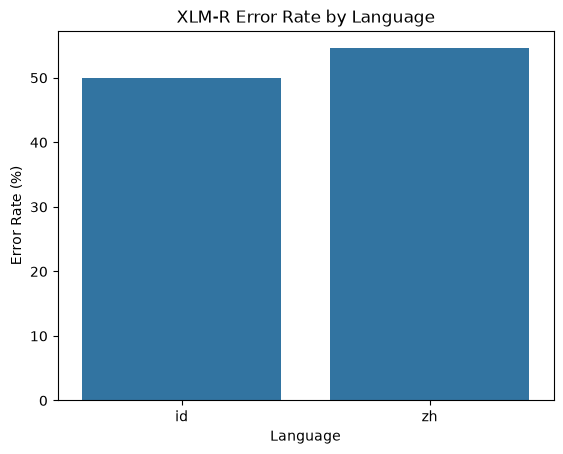

In [15]:
sns.barplot(
    data=xlmr_error.reset_index(),
    x='Language',
    y='error rate'
)

plt.title('XLM-R Error Rate by Language')
plt.ylabel('Error Rate (%)')
plt.xlabel('Language')
plt.show()